## 3.1 Volume et dynamique des écoutes

On regarde comment le total des écoutes du Top 200 change dans chaque pays : la tendance (3.1.1), les saisons (3.1.2) et les semaines exceptionnelles (3.1.3).

In [1]:

import pandas as pd
import matplotlib.pyplot as plt

CHEMIN_BASE = "base_complete.csv"

In [2]:

base = pd.read_csv(CHEMIN_BASE)
base["semaine"] = pd.to_datetime(base["semaine"])
base = base[base["semaine"] >= "2022-10-06"]

In [3]:

print(base.shape, base["pays"].nunique(), base["semaine"].nunique(), base.columns.tolist())

(419891, 11) 10 210 ['rank', 'uri', 'artist_names', 'track_name', 'source', 'peak_rank', 'previous_rank', 'weeks_on_chart', 'streams', 'pays', 'semaine']


### 3.1.1 Évolution du total des écoutes

Pour chaque pays et chaque semaine, on additionne les écoutes (streams) des 200 chansons du classement. Puis on trace une courbe par pays.

In [4]:

totaux = base.groupby(["pays", "semaine"])["streams"].sum().reset_index()

In [5]:
# On vérifie la taille du tableau et le plus petit total
print(totaux.shape, totaux["streams"].min())

(2100, 3) 5135953


In [6]:

pays_liste = totaux["pays"].unique()

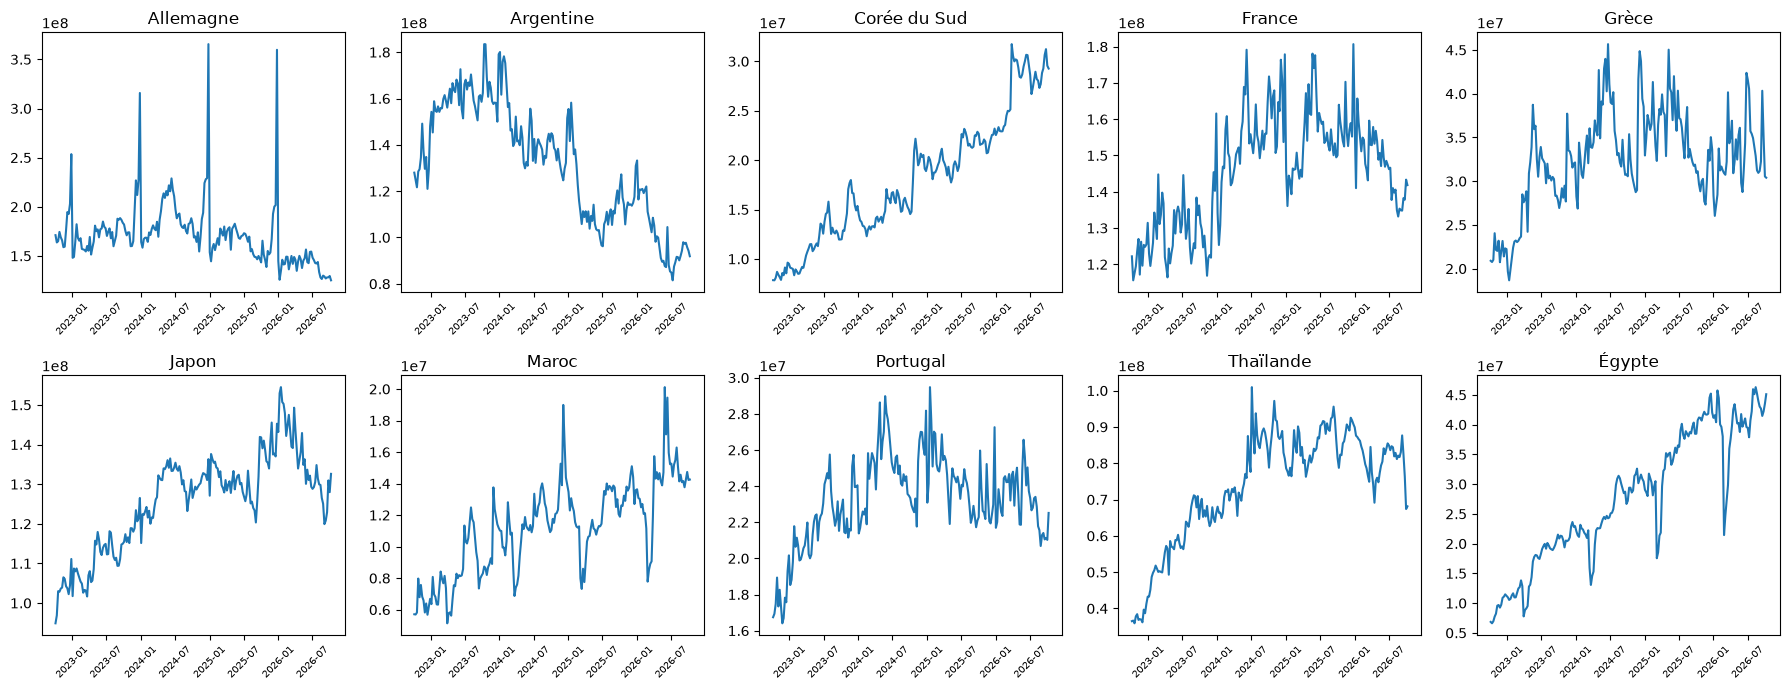

In [7]:

plt.figure(figsize=(18, 7))
for i in range(10):
    p = pays_liste[i]
    un_pays = totaux[totaux["pays"] == p]
    plt.subplot(2, 5, i + 1)
    plt.plot(un_pays["semaine"], un_pays["streams"])
    plt.title(p)
    plt.xticks(rotation=45, fontsize=7)
plt.tight_layout()
plt.show()

**Interprétations**

- Égypte et Corée du Sud : le total monte tout le temps. En Égypte, il y a aussi une forte baisse chaque printemps (mars-avril).
- Thaïlande et Japon : le total monte jusqu'en 2024, puis reste à peu près stable ou baisse un peu.
- Maroc : hausse en 2023, puis le total devient très irrégulier, avec de gros pics fin 2024 et mi-2026.
- France, Portugal, Grèce : hausse jusqu'à un niveau haut en 2024, puis baisse. Cela commence dès 2024 au Portugal et mi-2025 en France. En Grèce, le total varie beaucoup en 2025-2026.
- Argentine : niveau haut en 2023, puis baisse depuis début 2024, avec une chute nette début 2025.
- Allemagne : niveau plutôt plat, qui baisse en 2025-2026, avec un très gros pic chaque fin décembre.

Pour confirmer, on compare la moyenne des 4 premières semaines à celle des 4 dernières, pour chaque pays. Une moyenne sur 4 semaines évite qu'une semaine exceptionnelle change tout.

In [8]:

debut = totaux[totaux["semaine"] <= "2022-10-27"].groupby("pays")["streams"].mean()
fin = totaux[totaux["semaine"] >= "2026-09-17"].groupby("pays")["streams"].mean()
variation = (fin - debut) / debut * 100

resultat = pd.DataFrame({"debut": debut, "fin": fin, "variation_%": variation.round(1)})
print(resultat)

                     debut           fin  variation_%
pays                                                 
Allemagne     1.685546e+08  1.277431e+08        -24.2
Argentine     1.257255e+08  9.492123e+07        -24.5
Corée du Sud  8.118571e+06  3.017595e+07        271.7
France        1.186938e+08  1.403080e+08         18.2
Grèce         2.168234e+07  3.408876e+07         57.2
Japon         9.940037e+07  1.286121e+08         29.4
Maroc         6.299530e+06  1.437164e+07        128.1
Portugal      1.752690e+07  2.143008e+07         22.3
Thaïlande     3.673130e+07  7.358771e+07        100.3
Égypte        7.036186e+06  4.307063e+07        512.1




Les 4 premières semaines vont du 6 au 27 octobre 2022 et les 4 dernières du 17 septembre au 8 octobre 2026 : c'est à peu près la même période de l'année, donc la saison change peu la comparaison.

- 8 pays sur 10 sont en hausse. Les plus fortes : Égypte (+512 %), Corée du Sud (+272 %), Maroc (+128 %) et Thaïlande (+100 %). Les plus faibles : Grèce (+57 %), Japon (+29 %), Portugal (+22 %), France (+18 %).
- 2 pays sont en baisse : Argentine (−24,5 %) et Allemagne (−24,2 %).
- Pour l'Allemagne, les pics de Noël cachaient la baisse sur les courbes. La France, le Portugal et la Grèce baissent depuis 2024 ou 2025, mais restent au-dessus de leur niveau de 2022.

### 3.1.2 Saisons

On regarde si certains mois ont plus d'écoutes que d'autres. Pour cela, on compare chaque semaine à la moyenne de son année (ratio : 1 = dans la moyenne). On garde seulement les années complètes : 2023, 2024 et 2025.

In [9]:

totaux["annee"] = totaux["semaine"].dt.year
totaux["mois"] = totaux["semaine"].dt.month
print(totaux.groupby("annee")["semaine"].nunique())

annee
2022    13
2023    52
2024    52
2025    52
2026    41
Name: semaine, dtype: int64


In [10]:

complets = totaux[totaux["annee"].isin([2023, 2024, 2025])].copy()

moyennes = complets.groupby(["pays", "annee"])["streams"].mean().reset_index()
moyennes = moyennes.rename(columns={"streams": "moyenne_annee"})
complets = complets.merge(moyennes, on=["pays", "annee"], how="left")

complets["ratio"] = complets["streams"] / complets["moyenne_annee"]
print(complets.shape, complets["ratio"].mean())

(1560, 7) 1.0


In [11]:

saison = complets.groupby(["pays", "mois"])["ratio"].mean().reset_index()
print(saison.shape)
print(saison.head(12))

(120, 3)
         pays  mois     ratio
0   Allemagne     1  0.898970
1   Allemagne     2  0.937047
2   Allemagne     3  0.946280
3   Allemagne     4  0.975614
4   Allemagne     5  1.062360
5   Allemagne     6  1.051658
6   Allemagne     7  0.998699
7   Allemagne     8  0.942061
8   Allemagne     9  0.962295
9   Allemagne    10  0.921234
10  Allemagne    11  0.942610
11  Allemagne    12  1.392291


On trace le ratio moyen de chaque mois, pour chaque pays. La ligne en pointillé est la moyenne de l'année (ratio = 1) : au-dessus, le mois est plus fort que la moyenne ; en dessous, il est plus faible.

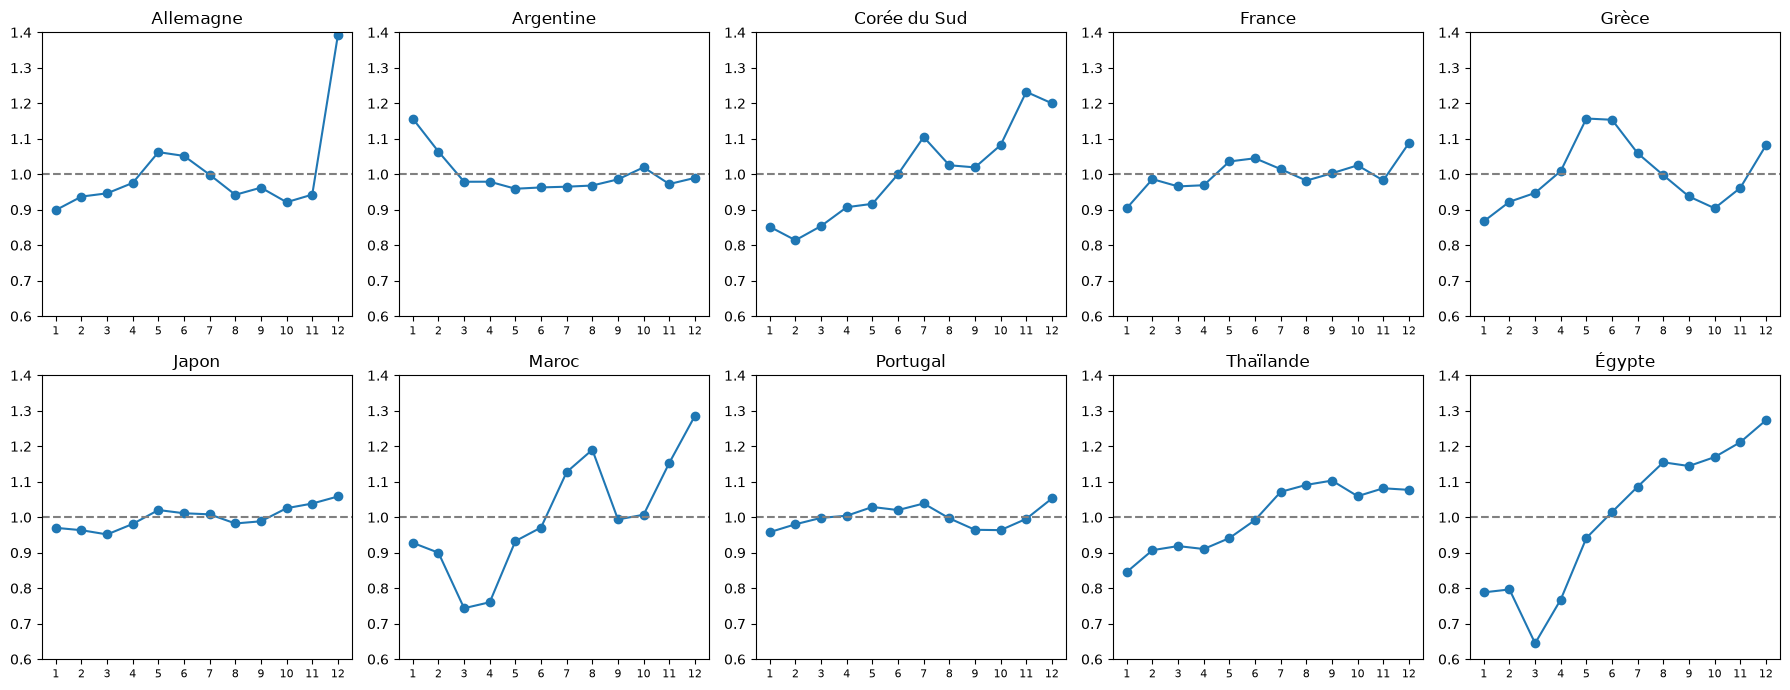

In [12]:

pays_liste = saison["pays"].unique()

plt.figure(figsize=(18, 7))
for i in range(10):
    p = pays_liste[i]
    s = saison[saison["pays"] == p]
    plt.subplot(2, 5, i + 1)
    plt.plot(s["mois"], s["ratio"], marker="o")
    plt.axhline(1, color="gray", linestyle="--")
    plt.title(p)
    plt.ylim(0.6, 1.4)
    plt.xticks(range(1, 13), fontsize=8)
plt.tight_layout()
plt.show()

Les mêmes valeurs en tableau, pour lire les chiffres exacts (un pays par ligne, un mois par colonne).

In [13]:

tableau = saison.pivot(index="pays", columns="mois", values="ratio").round(2)
print(tableau)

mois            1     2     3     4     5     6     7     8     9     10  \
pays                                                                       
Allemagne     0.90  0.94  0.95  0.98  1.06  1.05  1.00  0.94  0.96  0.92   
Argentine     1.16  1.06  0.98  0.98  0.96  0.96  0.96  0.97  0.99  1.02   
Corée du Sud  0.85  0.81  0.85  0.91  0.92  1.00  1.10  1.03  1.02  1.08   
France        0.90  0.99  0.97  0.97  1.04  1.05  1.01  0.98  1.00  1.03   
Grèce         0.87  0.92  0.95  1.01  1.16  1.15  1.06  1.00  0.94  0.90   
Japon         0.97  0.96  0.95  0.98  1.02  1.01  1.01  0.98  0.99  1.03   
Maroc         0.93  0.90  0.74  0.76  0.93  0.97  1.13  1.19  0.99  1.01   
Portugal      0.96  0.98  1.00  1.00  1.03  1.02  1.04  1.00  0.96  0.96   
Thaïlande     0.85  0.91  0.92  0.91  0.94  0.99  1.07  1.09  1.10  1.06   
Égypte        0.79  0.80  0.64  0.77  0.94  1.01  1.09  1.15  1.14  1.17   

mois            11    12  
pays                      
Allemagne     0.94  1.39  
Argent

**Interprétations**

- Décembre est au-dessus de la moyenne dans 9 pays sur 10, surtout en Allemagne (1,39), au Maroc (1,29) et en Égypte (1,27).
- L'Égypte et le Maroc ont un creux en mars-avril (entre 0,64 et 0,77).
- L'Égypte, la Thaïlande et la Corée du Sud sont plus hautes de juillet à septembre (le Maroc de juillet à août). Mais ces pays sont aussi en hausse sur toute la période : cela peut expliquer une partie de l'écart.
- Le Japon et le Portugal sont presque plats : il y a peu de saisons.


### 3.1.3 Semaines exceptionnelles

On cherche les semaines où le total d'un pays saute beaucoup par rapport à la semaine d'avant. Pour les plus gros sauts, on regarde quelles chansons et quels artistes dominent.

In [14]:

totaux["variation"] = totaux.groupby("pays")["streams"].pct_change()
print(totaux.sort_values("variation", ascending=False).head(10))

           pays    semaine    streams  annee  mois  variation
168   Allemagne 2025-12-25  359730985   2025    12   0.783057
116   Allemagne 2024-12-26  365493279   2024    12   0.595175
1320      Maroc 2023-11-30   13759510   2023    11   0.545373
952       Grèce 2024-11-28   41666440   2024    11   0.437623
64    Allemagne 2023-12-28  315791629   2023    12   0.390333
1263      Maroc 2022-10-27    7975149   2022    10   0.370386
1450      Maroc 2026-05-28   20118337   2026     5   0.367321
1373      Maroc 2024-12-05   18989802   2024    12   0.366298
898       Grèce 2023-11-16   37719631   2023    11   0.362758
2020     Égypte 2025-04-03   29673749   2025     4   0.359023


**Allemagne : les chansons les plus écoutées lors des trois semaines de fin décembre** (25 décembre 2025, 26 décembre 2024, 28 décembre 2023)

In [15]:

allemagne = base[base["pays"] == "Allemagne"]
sp = allemagne[allemagne["semaine"] == "2025-12-25"]
print(sp.sort_values("streams", ascending=False)[["artist_names", "track_name", "streams"]].head(10))

                artist_names  \
75592             Brenda Lee   
75593                  Wham!   
75594        Shakin' Stevens   
75595              Chris Rea   
75596           Mariah Carey   
75597          Ariana Grande   
75598          Michael Bublé   
75599            Dean Martin   
75600       Melanie Thornton   
75601  John Lennon, Yoko Ono   

                                              track_name  streams  
75592                  Rockin' Around The Christmas Tree  8890547  
75593                                     Last Christmas  8685284  
75594                           Merry Christmas Everyone  8326328  
75595         Driving Home for Christmas - 2019 Remaster  7716104  
75596                    All I Want for Christmas Is You  7639858  
75597                                      Santa Tell Me  7376407  
75598        It's Beginning to Look a Lot like Christmas  7185796  
75599             Let It Snow! Let It Snow! Let It Snow!  7146099  
75600  Wonderful Dream (Holidays Ar

In [16]:

allemagne = base[base["pays"] == "Allemagne"]
sp = allemagne[allemagne["semaine"] == "2024-12-26"]
print(sp.sort_values("streams", ascending=False)[["artist_names", "track_name", "streams"]].head(10))

          artist_names                                   track_name  streams
65192            Wham!                               Last Christmas  9763935
65193     Mariah Carey              All I Want for Christmas Is You  9753627
65194  Shakin' Stevens                     Merry Christmas Everyone  8387832
65195       Brenda Lee            Rockin' Around The Christmas Tree  7999489
65196      Dean Martin       Let It Snow! Let It Snow! Let It Snow!  7177306
65197   Kelly Clarkson                          Underneath the Tree  7096059
65198   José Feliciano                                Feliz Navidad  7002445
65199              Sia                                      Snowman  6691807
65200    Ariana Grande                                Santa Tell Me  6680076
65201    Michael Bublé  It's Beginning to Look a Lot like Christmas  6671294


In [17]:

allemagne = base[base["pays"] == "Allemagne"]
sp = allemagne[allemagne["semaine"] == "2023-12-28"]
print(sp.sort_values("streams", ascending=False)[["artist_names", "track_name", "streams"]].head(10))

           artist_names                                         track_name  \
54792             Wham!                    Last Christmas - Single Version   
54793      Mariah Carey                    All I Want for Christmas Is You   
54794   Shakin' Stevens                           Merry Christmas Everyone   
54795         Chris Rea         Driving Home for Christmas - 2019 Remaster   
54796       Dean Martin             Let It Snow! Let It Snow! Let It Snow!   
54797               Sia                                            Snowman   
54798  Melanie Thornton  Wonderful Dream (Holidays Are Coming) - Radio ...   
54799    Kelly Clarkson                                Underneath the Tree   
54800     Ariana Grande                                      Santa Tell Me   
54801        Brenda Lee                  Rockin' Around The Christmas Tree   

       streams  
54792  8299586  
54793  8131265  
54794  7270396  
54795  5800495  
54796  5676912  
54797  5604473  
54798  5058276  
54799

**Maroc et Grèce : les chansons les plus écoutées lors de leur plus gros saut** (30 novembre 2023 et 28 novembre 2024)

In [18]:

maroc = base[base["pays"] == "Maroc"]
sp = maroc[maroc["semaine"] == "2023-11-30"]
print(sp.sort_values("streams", ascending=False)[["artist_names", "track_name", "streams"]].head(10))

                artist_names                track_name  streams
305959          ElGrandeToto                  MAGHRIBI   678760
305960   ElGrandeToto, Hamza     DELLALI (feat. Hamza)   655290
305961          ElGrandeToto                   BGHAWNI   491193
305962          ElGrandeToto                    SULTAN   434821
305963          ElGrandeToto                        TP   410971
305964   ElGrandeToto, Morad     RAZONES (feat. Morad)   400898
305965          ElGrandeToto                 SARCELLES   379686
305966          ElGrandeToto                        27   366163
305967  ElGrandeToto, Oxlade  LIKE THAT (feat. Oxlade)   303751
305968          ElGrandeToto                       WOW   297849


In [19]:
# Les 10 chansons les plus écoutées en Grèce la semaine du 28 novembre 2024
grece = base[base["pays"] == "Grèce"]
sp = grece[grece["semaine"] == "2024-11-28"]
print(sp.sort_values("streams", ascending=False)[["artist_names", "track_name", "streams"]].head(10))

                artist_names       track_name  streams
190369       LEX, Dof Twogee       Nyxterides  1743227
190370       LEX, Dof Twogee    Alitiki Agapi  1649664
190371       LEX, Dof Twogee  Xeiroteri Genia  1423486
190372            LEX, Ortiz           Cognac  1143487
190373       LEX, Dof Twogee     3000 Strofes  1138729
190374       LEX, Dof Twogee         Graffiti  1135578
190375       LEX, Dof Twogee           F.K.A.  1121250
190376       LEX, Dof Twogee            24ora  1118863
190377            LEX, Ortiz       Breakdance  1095321
190378  LEX, Guè, Dof Twogee               SL   983191


**Part d'un seul artiste dans le total de la semaine** (écoutes de l'artiste divisées par les écoutes du Top 200 de la semaine)

In [20]:
# Maroc, semaine du 30 novembre 2023 : part de l'artiste ElGrandeToto dans le total de la semaine
maroc = base[base["pays"] == "Maroc"]
sp = maroc[maroc["semaine"] == "2023-11-30"]
streams_artiste = sp[sp["artist_names"].str.contains("ElGrandeToto")]["streams"].sum()
print(streams_artiste, sp["streams"].sum(), 100 * streams_artiste / sp["streams"].sum())

7336269 13759510 53.317807102142446


In [21]:
# Grèce, semaine du 28 novembre 2024 : part de l'artiste LEX dans le total de la semaine
grece = base[base["pays"] == "Grèce"]
sp = grece[grece["semaine"] == "2024-11-28"]
streams_artiste = sp[sp["artist_names"].str.contains("LEX")]["streams"].sum()
print(streams_artiste, sp["streams"].sum(), 100 * streams_artiste / sp["streams"].sum())

15036926 41666440 36.08881872317385


**Interprétations**

- Allemagne : fin décembre 2023, 2024 et 2025 (de +39 % à +78 %). Les trois années, les chansons les plus écoutées sont des chansons de Noël (par exemple Wham!, Mariah Carey, Shakin' Stevens).
- Maroc : semaine du 30 novembre 2023 (+55 %). Un seul artiste, ElGrandeToto, fait 53 % du Top 200 cette semaine-là, et ses titres sont tout le top 10.
- Grèce : semaine du 28 novembre 2024 (+44 %). Un seul artiste, LEX, fait 36 % du Top 200, et ses titres sont tout le top 10.



**À retenir de 3.1**

- Tendance : le total du Top 200 monte dans 8 pays sur 10 entre octobre 2022 et octobre 2026, surtout en Égypte, en Corée du Sud, au Maroc et en Thaïlande.
- Saisons : décembre est au-dessus de la moyenne dans 9 pays sur 10. L'Égypte et le Maroc ont un creux en mars-avril. Le Japon et le Portugal sont presque plats.
- Semaines exceptionnelles : en Allemagne, un pic à Noël chaque année. Au Maroc et en Grèce, une semaine dominée par un seul artiste.
- Pour la suite : la tendance et ces semaines peuvent changer les parts de musique nationale.

## 4.2 Indice de biais domestique

Pour chaque pays, on compare deux parts de musique nationale : sa part dans le Top 200 de son propre pays, et sa part dans les Top 200 des neuf autres pays.

indice = part de musique nationale dans son pays ÷ part de cette musique dans les 9 autres pays

Si l'indice est plus grand que 1, les gens écoutent plus leur musique nationale que les autres pays ne le font. Les parts sont calculées avec les écoutes (streams).

Une chanson est « nationale » si au moins un de ses artistes est du pays.

**Étape 1 : ajouter la nationalité et la langue à la base**

On charge les deux fichiers (la nationalité de chaque artiste, la langue de chaque chanson) et on les ajoute à la base. On vérifie qu'il n'y a pas de doublons dans les fichiers et que le nombre de lignes de la base ne change pas.

In [22]:

DOSSIER = ""
nat = pd.read_csv(DOSSIER + "artistes_nationalites.csv", keep_default_na=False)
lang = pd.read_csv(DOSSIER + "chansons_langues.csv", keep_default_na=False)

print(nat["artist_names"].duplicated().sum(), lang.duplicated(["artist_names", "track_name"]).sum())

lignes_avant = len(base)
base = base.merge(nat, on="artist_names", how="left")
base = base.merge(lang, on=["artist_names", "track_name"], how="left")

print(lignes_avant, len(base))
print(base[["nationalite", "langue"]].isna().sum())

0 0
419891 419891
nationalite    0
langue         0
dtype: int64


**Étape 2 : voir comment sont écrites les nouvelles colonnes**

Les nationalités sont des codes de pays à 2 lettres (FR, JP...) et les langues des codes à 3 lettres (eng, fra...). Quand une chanson a plusieurs artistes, il y a plusieurs nationalités séparées par un point-virgule.

In [23]:

print(base["nationalite"].value_counts().head(10))
print(base["langue"].value_counts().head(10))
print((base["nationalite"] == "").mean())

nationalite
US    50939
JP    37841
KR    34173
EG    32466
FR    28467
TH    25024
MA    21191
AR    20163
GR    18112
DE    16130
Name: count, dtype: int64
langue
eng    90549
ara    60941
spa    45596
ell    38540
jpn    37988
fra    36201
tha    31090
kor    24087
por    20920
deu    16738
Name: count, dtype: int64
0.0006858922910945936


In [24]:

autres = base[base["nationalite"].str.len() != 2]
print(len(autres) / len(base))
print(autres["nationalite"].value_counts().head(15))

0.15508072333057865
nationalite
GB;US    3334
KR;US    2905
GR;HK    1893
CA;US    1692
KR;JP    1551
GR;GB    1534
FR;US    1220
FR;BE    1179
GB;GR    1133
GR;US     981
DE;US     942
FR;MA     778
CO;PR     671
US;GB     667
AO;PT     637
Name: count, dtype: int64


**Étape 3 : Calcul de l'indice  pour les 10 pays**


In [25]:
codes = {"Allemagne": "DE", "Argentine": "AR", "Corée du Sud": "KR", "Égypte": "EG", "France": "FR",
         "Grèce": "GR", "Japon": "JP", "Maroc": "MA", "Portugal": "PT", "Thaïlande": "TH"}

resultats = []

for nom, code in codes.items():
    chez_lui = base[base["pays"] == nom]
    autres = base[base["pays"] != nom]
    part_chez_lui = chez_lui[chez_lui["nationalite"].str.contains(code)]["streams"].sum() / chez_lui["streams"].sum()
    part_ailleurs = autres[autres["nationalite"].str.contains(code)]["streams"].sum() / autres["streams"].sum()
    resultats.append([nom, part_chez_lui, part_ailleurs, part_chez_lui / part_ailleurs])

indices = pd.DataFrame(resultats, columns=["pays", "part_chez_lui", "part_ailleurs", "indice"])
print(indices.round(6))

           pays  part_chez_lui  part_ailleurs        indice
0     Allemagne       0.458554       0.008490     54.009541
1     Argentine       0.593449       0.000836    709.908956
2  Corée du Sud       0.776326       0.037197     20.870690
3        Égypte       0.826206       0.000048  17345.976376
4        France       0.696222       0.017639     39.470792
5         Grèce       0.685312       0.000126   5419.369517
6         Japon       0.870162       0.009428     92.294043
7         Maroc       0.645982       0.001114    579.857560
8      Portugal       0.247014       0.000005  45563.872879
9     Thaïlande       0.608657       0.000095   6401.579269


**Étape 4 : graphique de l'indice**

Les indices vont de 21 à plus de 45 000. On utilise une échelle logarithmique pour tout voir sur le même graphique.

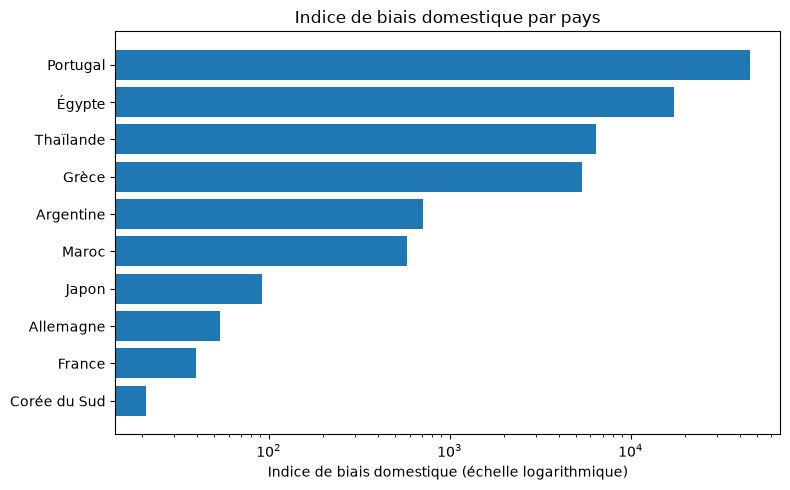

In [26]:
# Graphique à barres : un indice par pays, du plus petit au plus grand
indices = indices.sort_values("indice")

plt.figure(figsize=(8, 5))
plt.barh(indices["pays"], indices["indice"])
plt.xscale("log")
plt.xlabel("Indice de biais domestique (échelle logarithmique)")
plt.title("Indice de biais domestique par pays")
plt.tight_layout()
plt.show()

Le même graphique avec une couleur par groupe : bleu = pays avec quota (France, Portugal, Argentine, Grèce), gris = pays sans quota.

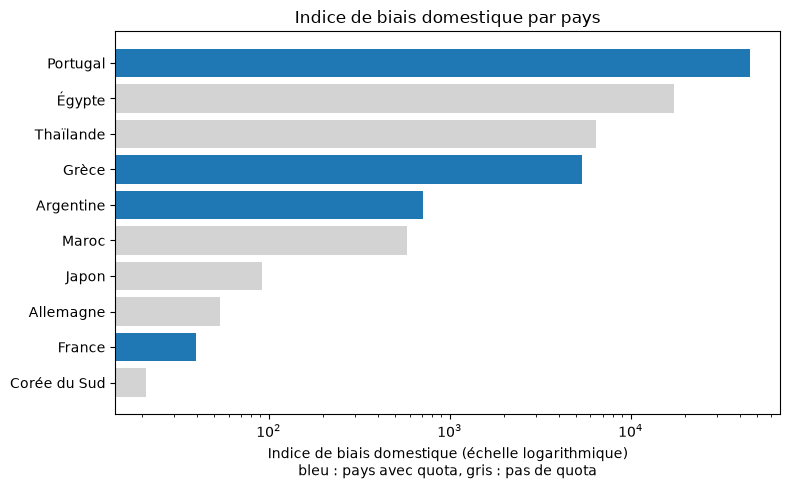

In [27]:

groupes = {"France": "quota", "Portugal": "quota", "Argentine": "quota", "Grèce": "quota",
           "Allemagne": "pas de quota", "Japon": "pas de quota", "Thaïlande": "pas de quota",
           "Corée du Sud": "pas de quota", "Maroc": "pas de quota", "Égypte": "pas de quota"}
couleurs = {"quota": "tab:blue", "pas de quota": "lightgray"}

indices["groupe"] = indices["pays"].map(groupes)

plt.figure(figsize=(8, 5))
plt.barh(indices["pays"], indices["indice"], color=indices["groupe"].map(couleurs))
plt.xscale("log")
plt.xlabel("Indice de biais domestique (échelle logarithmique)\nbleu : pays avec quota, gris : pas de quota")
plt.title("Indice de biais domestique par pays")
plt.tight_layout()
plt.show()

**Ce que montre l'indice**

- Dans les 10 pays, la musique nationale pèse beaucoup dans le Top 200 du pays : de 25 % (Portugal) à 87 % (Japon) des écoutes. Les indices sont tous bien plus grands que 1.
- Les indices sont très différents : de 21 (Corée du Sud) à plus de 45 000 (Portugal). Du plus haut au plus bas : Portugal, Égypte, Thaïlande, Grèce, Argentine, Maroc, Japon, Allemagne, France, Corée du Sud.
- On ne voit pas de séparation claire entre pays avec quota et sans quota : le Portugal (quota) est premier, la Grèce (quota) quatrième, l'Argentine (quota) cinquième, la France (quota) neuvième, et l'Égypte et la Thaïlande (sans quota) ont des indices très élevés.



**À retenir de 4.2**

- La musique nationale fait de 25 % (Portugal) à 87 % (Japon) des écoutes du Top 200 de son pays : il y a un biais domestique dans les 10 pays.
- Les indices vont de 21 à plus de 45 000.
- On ne voit pas de séparation claire entre pays avec quota et sans quota.

## 6. Discussion : quotas et culture

### 6.1 Ce que montrent les chiffres

Dans les dix pays, les gens écoutent beaucoup leur musique nationale, avec ou sans quota. Au Japon, 87 % des écoutes du Top 200 vont à des artistes japonais. Au Portugal, c'est seulement 25 % (partie 4.2). Les pays sans quota ne sont pas les moins tournés vers leur musique : le Japon fait 87 %, l'Égypte 83 % et la Corée du Sud 78 %.

Dans la partie 4.1, nous avons comparé les pays avec quota (Argentine, France, Grèce, Portugal) aux six autres. Les pays avec quota ont moins de musique nationale : 53,1 % contre 63,2 %. Si les quotas faisaient monter la musique nationale, on verrait le contraire. Si on met la Grèce et le Maroc de côté, l'écart est encore plus grand (48,9 % contre 65,9 %). Les pays avec quota ont plus de chansons dans leur langue (71,6 % contre 59,3 %).

On ne voit pas de séparation claire entre les deux groupes. Parmi les pays avec quota, la musique nationale va de 25 % au Portugal à 70 % en France. Dans le calcul de la partie 4.3, on compare le même titre, la même semaine, dans plusieurs pays. Dans les pays avec quota, la langue compte (+84 % d'écoutes), mais pas la nationalité. Dans les pays sans quota, c'est la nationalité qui compte (+70 %).

Les courbes de la partie 3.1 se ressemblent pour la France, le Portugal, la Grèce et l'Argentine : le total du Top 200 monte, puis baisse à partir de 2024 ou 2025. L'Allemagne, sans quota, baisse aussi (−24 %). L'Égypte, la Corée du Sud, le Maroc et la Thaïlande, eux, montent. Dans la partie 5, les pays les plus proches sont l'Allemagne et le Portugal, puis la Corée du Sud et la Thaïlande.

Les pays les plus tournés vers leur musique sont le Japon, l'Égypte et la Corée du Sud. Les plus ouverts sont le Portugal (25 %) et l'Allemagne (46 %), qui écoutent aussi beaucoup d'anglais (42 % et 55 % des écoutes, partie 4.1).

### 6.2 D'autres explications possibles

- **La langue.** Le Japon et la Thaïlande ont une langue que personne d'autre ne parle dans notre échantillon, et l'Égypte ne la partage qu'avec le Maroc. Leurs classements changent peu (partie 3.2), et le Japon et l'Égypte écoutent très peu d'anglais (9,7 % et 8,1 %).
- **La taille du marché.** Le Top 200 allemand fait environ 128 à 169 millions d'écoutes par semaine (début et fin de période). Celui de l'Égypte en fait 7 à 43 millions et celui du Maroc 6 à 14 millions. Dans un petit marché, un seul artiste peut tout changer : au Maroc, une semaine, ElGrandeToto fait 53 % du Top 200.
- **L'anglais.** L'Allemagne (55,4 %) et le Portugal (41,5 %) écoutent beaucoup d'anglais, et ce sont les pays avec le moins de musique nationale. Ce n'est pas vrai partout : la Corée du Sud a 71,8 % d'anglais (partie 4.1) et 78 % de musique nationale (partie 4.2). Ce chiffre d'anglais doit encore être contrôlé, comme le dit la partie 4.1.
- **Spotify.** Notre base ne contient que le Top 200 de Spotify, pas toute l'écoute d'un pays. Nous n'avons pas pu tester cette piste.

### 6.3 Pourquoi on ne conclut pas sur l'effet des quotas

1. Les quotas concernent la radio, et nous n'avons que des écoutes sur Spotify. Nous ne voyons pas la radio.
2. Les quotas existaient déjà avant le début de nos données (France 1986, Portugal 2001, Argentine 2009). Nous ne pouvons donc pas comparer « avant » et « après ». Seule la mesure grecque (2024) commence pendant notre période, et elle concerne les lieux publics, pas la radio.
3. Les pays avec et sans quota sont très différents : la langue, la taille du marché. Nous n'avons que dix pays.
4. Le résultat change selon la façon de classer la Grèce et le Maroc (53,1 % contre 63,2 % d'un côté, 48,9 % contre 65,9 % de l'autre).
5. Un pays met peut-être un quota parce que sa musique nationale est faible, comme le Portugal. Le quota serait alors la conséquence, pas la cause.
6. Les quotas ne sont pas tous les mêmes : 30 % en Argentine, 40 % en France et en Grèce, 30 % aujourd'hui au Portugal. Quand on compare seulement deux pays dans le calcul de la partie 4.3, il y a peu de lignes (5 982 et 8 388), donc le résultat est peu précis.

### 6.4 Ce que l'étude apporte malgré tout

- Nous avons comparé dix pays sur la même période : 210 semaines et 419 891 lignes.
- Les gens écoutent plus la musique de leur pays partout. Un même titre est écouté environ 41 % de plus là où un artiste est du pays, et 44 % de plus là où il est chanté dans la langue du pays.
- Les quotas ne sont pas nécessaires pour cela : le Japon, l'Égypte et la Corée du Sud n'ont pas de quota dans notre fichier et sont les plus tournés vers leur musique.
- Les classements restent différents d'un pays à l'autre : deux pays n'ont en moyenne que 3,5 % de titres en commun.
- Pour aller plus loin : avoir des données de radio, et regarder avant et après la mesure de la Grèce (2024).